# Estimation de $\pi$ par la méthode de Monte-Carlo
## Principe de la méthode
Le principe de la méthode consiste à :
* Fixer une valeur $nb$ ;
* Réaliser $nb$ tirages aléatoires de paires $(x, y)$ de nombres entre -1 et 1
* Compter le nombre de paires aléatoires vérifiant $x^2 + y^2 \leq 1$ : notons $dc$ ce nombre ($dc$ est ici une abréviation pour "dans le cercle", voir explications ci-après)
* L'estimation de $\pi$ est donnée par la valeur de : $\frac{4 \text{dc}}{\text{nb}}$.

## Quelques explications complémentaires
(normalement inutile pour programmer le calcul)

* Une paire $(x, y)$ de nombres entre -1 et 1 représente un point situé dans le carré centré en $(0, 0)$ et de côté de longueur $2$ (et donc de surface 4 puisque la surface d'un carré de côté de longueur $c$ est $c^2$)

* Une paire $(x, y)$ qui vérifie $x^2 + y^2 \leq 1$ représente un point situé dans le cercle unité (la surface de ce cercle est $\pi$ puisque la surface d'un cercle de rayon $r$ est $\pi r^2$).

* Avec le tirage d'un grand nombre de points qui se répartissent uniformément dans le carré, le rapport donne l'estimation de $\pi$.

## Remarque :
La convergence du calcul est lent.

## Module pour gérer des tirages aléatoires de nombres
Le module random contient des fonctionnalités permettant de simuler des tirages aléatoires de nombres.

In [2]:
import random

*Remarque.* Il peut être conseillé d'importer un module complet plutôt que son contenu c'est-à-dire il est préférable d'écrire *import module* plutôt que *from module import*. Si la deuxième méthode oblige à préfixer les fonctions à utiliser le nom du module (sur le modèle : *module.fonction( )*, elle évite que l'import du contenu du module écrase la définition d'une fonction de même nom définie par l'utilisateur.
Accessoirement ici, cela permet d'avoir l'aide séparée sur la fonction random. Avec un *import random¨, il aurait fallu consulter l'ensemble de l'aide sur le module "random" (voir instruction suivante si curiosité ou besoin ultérieurement).

Le module *random* contient une fonction *random( )*. L'instruction suivante permet de consulter ses spécifications.

In [2]:
help(random.random)

Help on built-in function random:

random(...) method of random.Random instance
    random() -> x in the interval [0, 1).



*Remarque*. Il est possible aussi de consulter la documentation sur le module complet

In [3]:
help(random) # ou help("random") 
             # si on avait fait "from random import *"

Help on module random:

NAME
    random - Random variable generators.

MODULE REFERENCE
    https://docs.python.org/3.7/library/random
    
    The following documentation is automatically generated from the Python
    source files.  It may be incomplete, incorrect or include features that
    are considered implementation detail and may vary between Python
    implementations.  When in doubt, consult the module reference at the
    location listed above.

DESCRIPTION
        integers
        --------
               uniform within range
    
        sequences
        ---------
               pick random element
               pick random sample
               pick weighted random sample
               generate random permutation
    
        distributions on the real line:
        ------------------------------
               uniform
               triangular
               normal (Gaussian)
               lognormal
               negative exponential
               gamma
             

*Question*. Comment tirer au hasard un nombre dans l'intervalle [-1, 1) en utilisant la fonction random( ).

In [6]:
# Testez ici votre réponse
random.random()*2-1

0.14669929510374935

*Question*. Avec quelle fonction du module random est-il possible d'avoir le même résultat ?

**Remarque pédagogique.** L'objectif est d'amener les étudiants à lire les aides.


In [12]:
# Testez ici cette fonction
random.uniform(-1, 1)

0.8915505415831055

In [13]:
help(random.uniform)

Help on method uniform in module random:

uniform(a, b) method of random.Random instance
    Get a random number in the range [a, b) or [a, b] depending on rounding.



## Exercice
Compléter la cellule suivante avec une séquence d'instructions mettant en oeuvre la méthode de Monte-Carlo.
Vous établirez votre code au départ avec nb=10, puis quand vous penserez qu'il fonctionne, vous l'exécuterez avec des valeurs de nb de plus en plus grande : nb = 100, 1 000, ..., 1 000 000, ..., 100 000 000.

In [2]:
# Ici votre mise en oeuvre de Monte-Carlo
# avec affichage d'une estimation de pi
nb = 1000000
dc = 0
for i in range(nb): 
    # ou for i in range(0, nb, 1): 
    #    mais ici on veut juste réaliser nb fois une opération : 
    #    les valeurs exactes de i n'ont pas d'importance
    x, y  = random.uniform(-1,1), random.uniform(-1,1)
    if x*x + y*y <= 1:
        dc += 1
print( 4 * dc/nb)

3.145336


En exécutant le code précédent à plusieurs reprises, vous devriez vérifier que les résultats ne sont pas toujours les mêmes (les valeurs aléatoires utilisées ne sont donc pas toujours identiques).

## Exercice
Modifier le code pour permettre, en plus de l'affichage de l'estimation de $\pi$ de stocker :
* dans une variable *lxin* : la liste des abscisses *x* des points *(x, y)* à l'intérieur du cercle unité,
* dans une variable *lyin* : la liste des ordonnées *y* des points *(x, y)* à l'intérieur du cercle unité,
* dans une variable *lxout* : la liste des abscisses *x* des points *(x, y)* à l'extérieur du cercle unité,
* dans une variable *lyout* : la liste des ordonnées *x* des points *(x, y)* à l'extérieur du cercle unité.

*Remarque*. Du point de vue de la gestion des données, il serait préférable de stocker des listes de couples *(x, y)*. Nous ne le faisons pas car les listes *lxin*, *lyin*, *lxout* et *lyout* sont calculées en vue de la visualisation à suivre. Calculer une liste de points nous obligeraient à calculer ces listes ensuites. Il est inutile ici de le faire en deux temps.

*Rappels sur les listes*:
* La liste vide se note [ ]
* La méthode *append( )* d'un objet de type list permet d'ajouter un élément en fin de liste (la complexité de cette méthode est en O(1) - voir https://wiki.python.org/moin/TimeComplexity pour des informations sur la complexité de nombreuses opérations de base en Python).

In [5]:
# Ici votre mise en oeuvre modifiée de Monte-Carlo
# avec sauvegarde des points
# avec affichage d'une estimation de pi
nb = 1000000
dc = 0
lxin = []
lyin = []
lxout = []
lyout = []
for i in range(0, nb, 1):
    x = random.uniform(-1,1)
    y = random.uniform(-1,1)
    if x*x + y*y <= 1:
        dc += 1
        lxin.append(x)
        lyin.append(y)
    else:
        lxout.append(x)
        lyout.append(y)
print(4*dc/nb)

3.141088


Si vous avez bien réalisé le travail précédent, la cellule suivante vous permet de visualiser les points tirés au hasard. Attention&nbsp;! Plus la valeur de *nb* est grande, plus le temps de calcul est long (il peut ne pas être immédiat) mais plus la précision du dessin peut être grande.

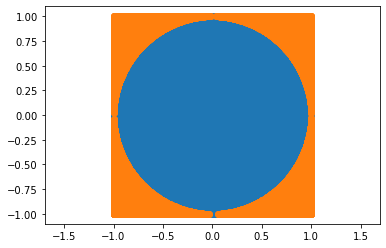

In [6]:
# Visualisation du tirage aléatoire
# La ligne suivante permet l'affichage de la visualisation
    # dans le notebook et non en fenêtre popup
%matplotlib inline  
from matplotlib import pyplot as plt 
plt.scatter(lxin, lyin)
plt.scatter(lxout, lyout)
plt.axis("equal")
plt.show()